In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("Weather_data.csv")

In [3]:
df.info

<bound method DataFrame.info of                    District          Mandal       Date  Rain (mm)  \
0                  Adilabad  Adilabad Rural  01-Feb-23        0.0   
1                  Adilabad  Adilabad Rural  02-Feb-23        0.0   
2                  Adilabad  Adilabad Rural  03-Feb-23        0.0   
3                  Adilabad  Adilabad Rural  04-Feb-23        0.0   
4                  Adilabad  Adilabad Rural  05-Feb-23        0.0   
...                     ...             ...        ...        ...   
445207  Yadadri Bhuvanagiri   Yadagirigutta  27-Jan-25        0.0   
445208  Yadadri Bhuvanagiri   Yadagirigutta  28-Jan-25        0.0   
445209  Yadadri Bhuvanagiri   Yadagirigutta  29-Jan-25        0.0   
445210  Yadadri Bhuvanagiri   Yadagirigutta  30-Jan-25        0.0   
445211  Yadadri Bhuvanagiri   Yadagirigutta  31-Jan-25        0.0   

        Min Temp (°C)  Max Temp (°C)  Min Humidity (%)  Max Humidity (%)  \
0                16.6           30.9              49.3         

In [4]:
df.shape

(445212, 10)

In [5]:
df.head(10)

,District,Mandal,Date,Rain (mm),Min Temp (°C),Max Temp (°C),Min Humidity (%),Max Humidity (%),Min Wind Speed (Kmph),Max Wind Speed (Kmph)
0,Adilabad,Adilabad Rural,01-Feb-23,0.0,16.6,30.9,49.3,82.0,0.0,11.4
1,Adilabad,Adilabad Rural,02-Feb-23,0.0,13.7,28.7,46.4,81.1,0.0,12.0
2,Adilabad,Adilabad Rural,03-Feb-23,0.0,10.3,29.5,24.2,55.8,0.0,10.9
3,Adilabad,Adilabad Rural,04-Feb-23,0.0,11.7,30.3,26.3,59.9,0.0,16.7
4,Adilabad,Adilabad Rural,05-Feb-23,0.0,9.2,31.3,25.2,57.6,0.0,9.7
5,Adilabad,Adilabad Rural,06-Feb-23,0.0,10.6,32.2,19.7,70.7,0.0,13.6
6,Adilabad,Adilabad Rural,07-Feb-23,0.0,18.2,32.7,23.8,69.7,0.0,8.9
7,Adilabad,Adilabad Rural,08-Feb-23,0.0,15.3,33.4,34.4,80.8,0.0,8.0
8,Adilabad,Adilabad Rural,09-Feb-23,0.0,12.1,32.5,32.7,84.3,0.0,13.0
9,Adilabad,Adilabad Rural,10-Feb-23,0.0,12.2,34.1,22.0,58.9,0.0,11.9


In [6]:
df.tail(10)

,District,Mandal,Date,Rain (mm),Min Temp (°C),Max Temp (°C),Min Humidity (%),Max Humidity (%),Min Wind Speed (Kmph),Max Wind Speed (Kmph)
445202,Yadadri Bhuvanagiri,Yadagirigutta,22-Jan-25,0.0,15.2,37.8,38.8,80.9,0.0,2.2
445203,Yadadri Bhuvanagiri,Yadagirigutta,23-Jan-25,0.0,17.6,35.0,46.2,86.8,0.0,5.9
445204,Yadadri Bhuvanagiri,Yadagirigutta,24-Jan-25,0.0,16.9,32.7,55.7,88.2,0.0,7.1
445205,Yadadri Bhuvanagiri,Yadagirigutta,25-Jan-25,0.0,15.7,33.4,50.5,88.7,0.0,6.0
445206,Yadadri Bhuvanagiri,Yadagirigutta,26-Jan-25,0.0,17.3,34.8,47.4,79.7,0.0,5.4
445207,Yadadri Bhuvanagiri,Yadagirigutta,27-Jan-25,0.0,17.0,35.2,46.0,77.6,0.0,4.6
445208,Yadadri Bhuvanagiri,Yadagirigutta,28-Jan-25,0.0,16.6,35.6,41.5,83.0,0.0,0.8
445209,Yadadri Bhuvanagiri,Yadagirigutta,29-Jan-25,0.0,17.3,34.9,48.4,81.9,0.0,8.6
445210,Yadadri Bhuvanagiri,Yadagirigutta,30-Jan-25,0.0,18.0,32.7,52.6,86.8,0.0,3.9
445211,Yadadri Bhuvanagiri,Yadagirigutta,31-Jan-25,0.0,17.6,33.1,55.7,86.3,0.0,6.0


In [7]:
df.isnull().sum

<bound method DataFrame.sum of         District  Mandal   Date  Rain (mm)  Min Temp (°C)  Max Temp (°C)  \
0          False   False  False      False          False          False   
1          False   False  False      False          False          False   
2          False   False  False      False          False          False   
3          False   False  False      False          False          False   
4          False   False  False      False          False          False   
...          ...     ...    ...        ...            ...            ...   
445207     False   False  False      False          False          False   
445208     False   False  False      False          False          False   
445209     False   False  False      False          False          False   
445210     False   False  False      False          False          False   
445211     False   False  False      False          False          False   

        Min Humidity (%)  Max Humidity (%)  Min Wind Spe

In [8]:
df.duplicated().sum

<bound method Series.sum of 0         False
1         False
2         False
3         False
4         False
          ...  
445207    False
445208    False
445209    False
445210    False
445211    False
Length: 445212, dtype: bool>

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
for col in ["District", "Mandal"]:
    df[col] = df[col].astype("string").str.strip()

In [11]:
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%b-%y",
    errors="coerce"
)

In [12]:
# 6. Convert numerical columns
numeric_cols = [
    "Rain (mm)",
    "Min Temp (°C)",
    "Max Temp (°C)",
    "Min Humidity (%)",
    "Max Humidity (%)",
    "Min Wind Speed (Kmph)",
    "Max Wind Speed (Kmph)"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [13]:
# 7. Handle invalid temperature values
df.loc[
    df["Min Temp (°C)"] > df["Max Temp (°C)"],
    ["Min Temp (°C)", "Max Temp (°C)"]
] = np.nan

In [14]:
# 8. Handle invalid humidity values
df.loc[
    df["Min Humidity (%)"] > df["Max Humidity (%)"],
    ["Min Humidity (%)", "Max Humidity (%)"]
] = np.nan

In [15]:
# 9. Handle humidity range (0–100)
for col in ["Min Humidity (%)", "Max Humidity (%)"]:
    df.loc[
        (df[col] < 0) | (df[col] > 100),
        col
    ] = np.nan

In [16]:
# 10. Save cleaned dataset
df["Date"] = df["Date"].dt.strftime("%Y-%m-%d")

In [17]:
df.to_csv("weather_data_cleaned.csv", index=False)

In [18]:
print("\nCleaned Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Cleaning Completed Successfully!")

print("\nCleaned Dataset:")
print(df.head())


Cleaned Dataset Shape: (445212, 10)

Missing Values After Cleaning:
District                  0
Mandal                    0
Date                      0
Rain (mm)                 0
Min Temp (°C)             3
Max Temp (°C)             3
Min Humidity (%)         25
Max Humidity (%)         20
Min Wind Speed (Kmph)     0
Max Wind Speed (Kmph)     0
dtype: int64

Duplicate Rows: 0

Data Cleaning Completed Successfully!

Cleaned Dataset:
   District          Mandal        Date  Rain (mm)  Min Temp (°C)  \
0  Adilabad  Adilabad Rural  2023-02-01        0.0           16.6   
1  Adilabad  Adilabad Rural  2023-02-02        0.0           13.7   
2  Adilabad  Adilabad Rural  2023-02-03        0.0           10.3   
3  Adilabad  Adilabad Rural  2023-02-04        0.0           11.7   
4  Adilabad  Adilabad Rural  2023-02-05        0.0            9.2   

   Max Temp (°C)  Min Humidity (%)  Max Humidity (%)  Min Wind Speed (Kmph)  \
0           30.9              49.3              82.0                

#2.Visualization

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
# Convert Date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Set visualization style
sns.set_style("whitegrid")

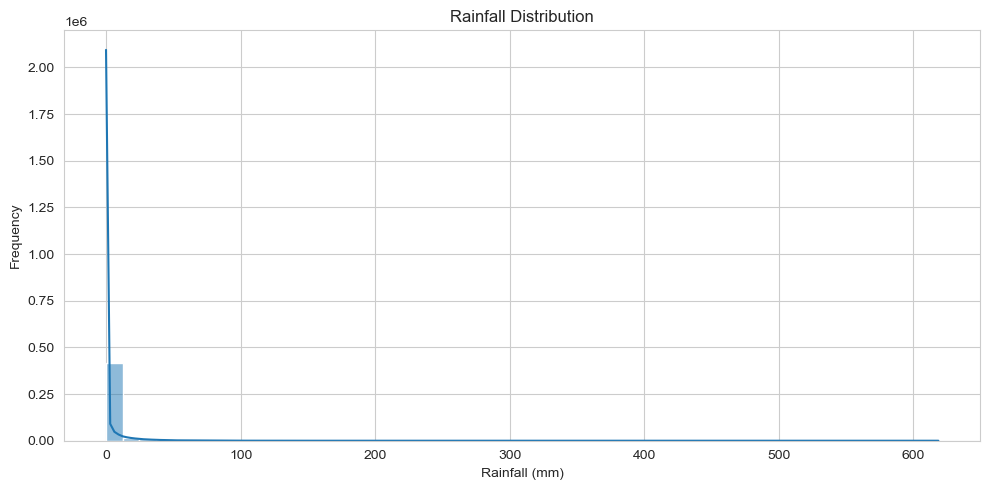

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Rain (mm)"].dropna(),
    bins=50,
    kde=True
)

plt.title("Rainfall Distribution")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

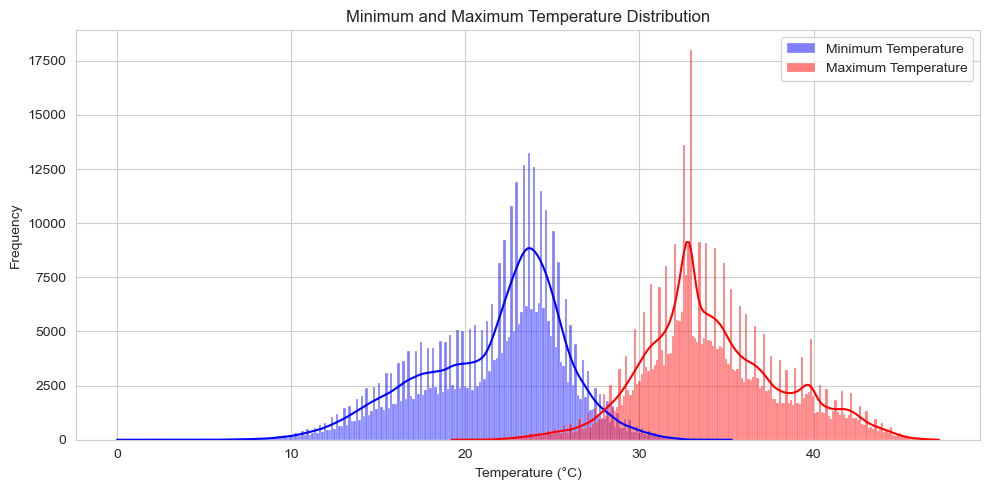

<Figure size 640x480 with 0 Axes>

In [22]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Min Temp (°C)"],
    color="blue",
    label="Minimum Temperature",
    kde=True,
    alpha=0.5
)

sns.histplot(
    df["Max Temp (°C)"],
    color="red",
    label="Maximum Temperature",
    kde=True,
    alpha=0.5
)

plt.title("Minimum and Maximum Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()
plt.savefig("Minimum and Maximum Temperature Distribution",dpi = 300)

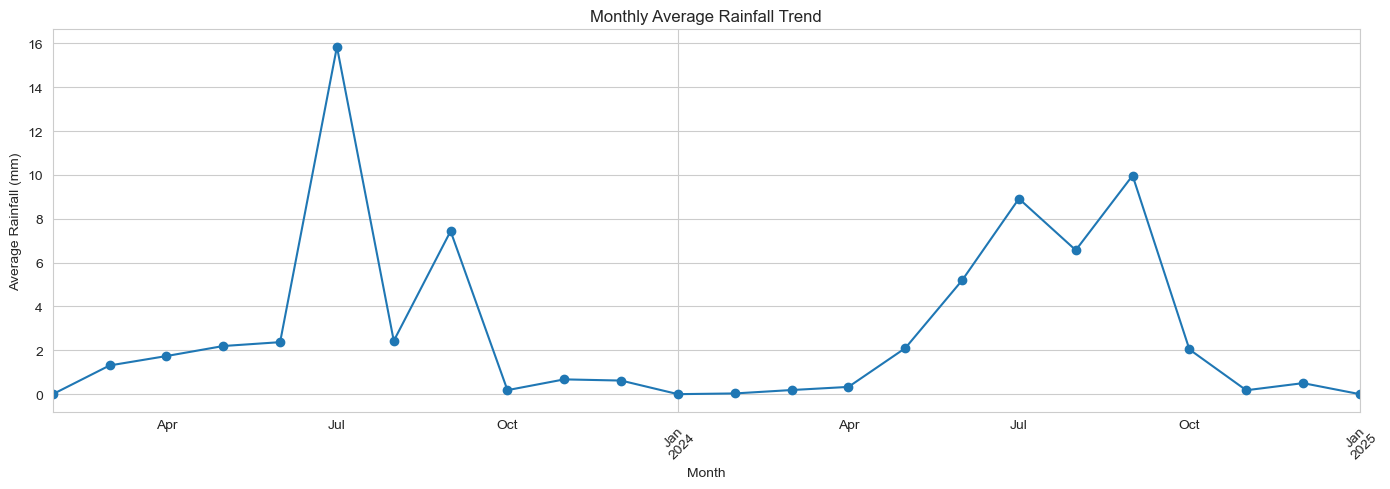

<Figure size 640x480 with 0 Axes>

In [23]:
monthly_rain = df.groupby(
    df["Date"].dt.to_period("M")
)["Rain (mm)"].mean()

plt.figure(figsize=(14, 5))

monthly_rain.plot(kind="line", marker="o")

plt.title("Monthly Average Rainfall Trend")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.savefig("Monthly raainfall analysis",dpi=300)

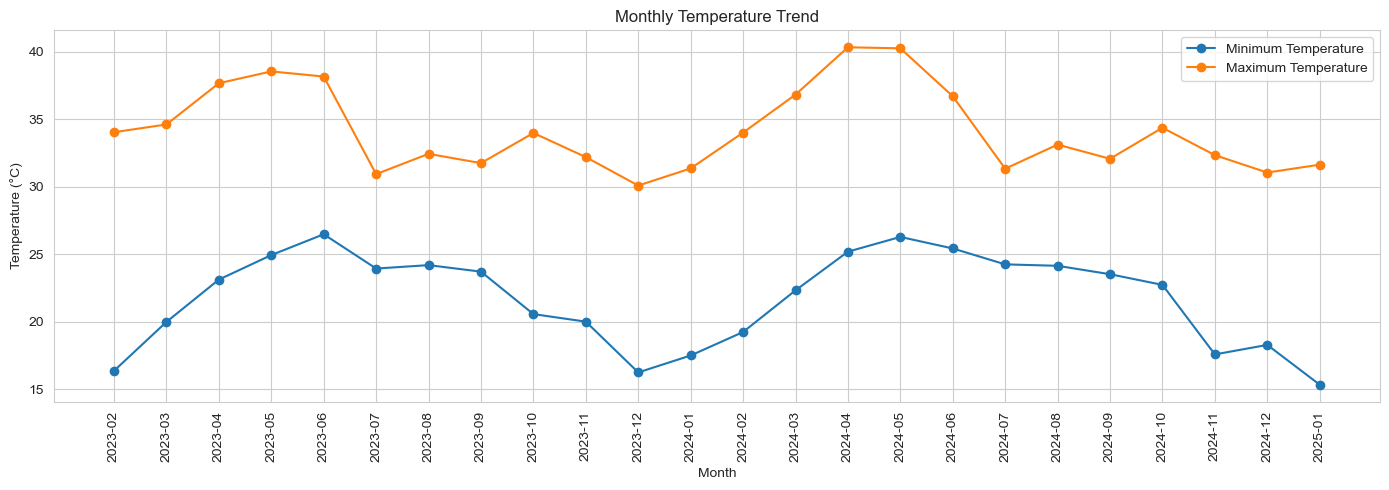

In [24]:
monthly_temp = df.groupby(
    df["Date"].dt.to_period("M")
)[["Min Temp (°C)", "Max Temp (°C)"]].mean()

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_temp.index.astype(str),
    monthly_temp["Min Temp (°C)"],
    label="Minimum Temperature",
    marker="o"
)

plt.plot(
    monthly_temp.index.astype(str),
    monthly_temp["Max Temp (°C)"],
    label="Maximum Temperature",
    marker="o"
)

plt.title("Monthly Temperature Trend")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

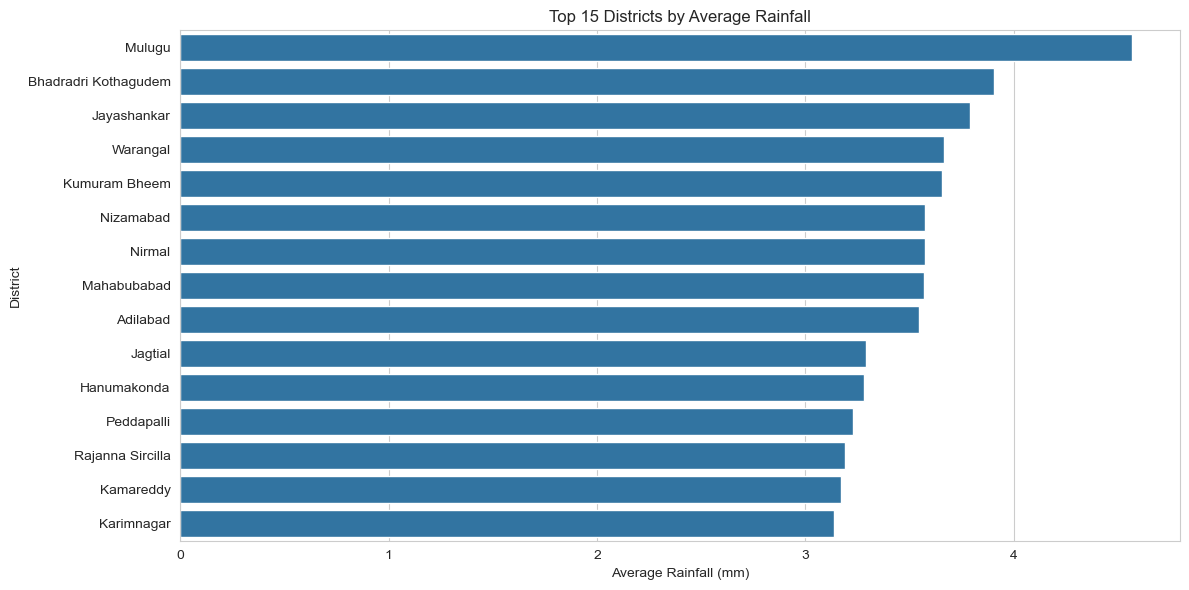

<Figure size 640x480 with 0 Axes>

In [25]:
district_rain = df.groupby(
    "District"
)["Rain (mm)"].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=district_rain.values,
    y=district_rain.index
)

plt.title("Top 15 Districts by Average Rainfall")
plt.xlabel("Average Rainfall (mm)")
plt.ylabel("District")
plt.tight_layout()
plt.show()
plt.savefig("districts rainfall",dpi = 300)

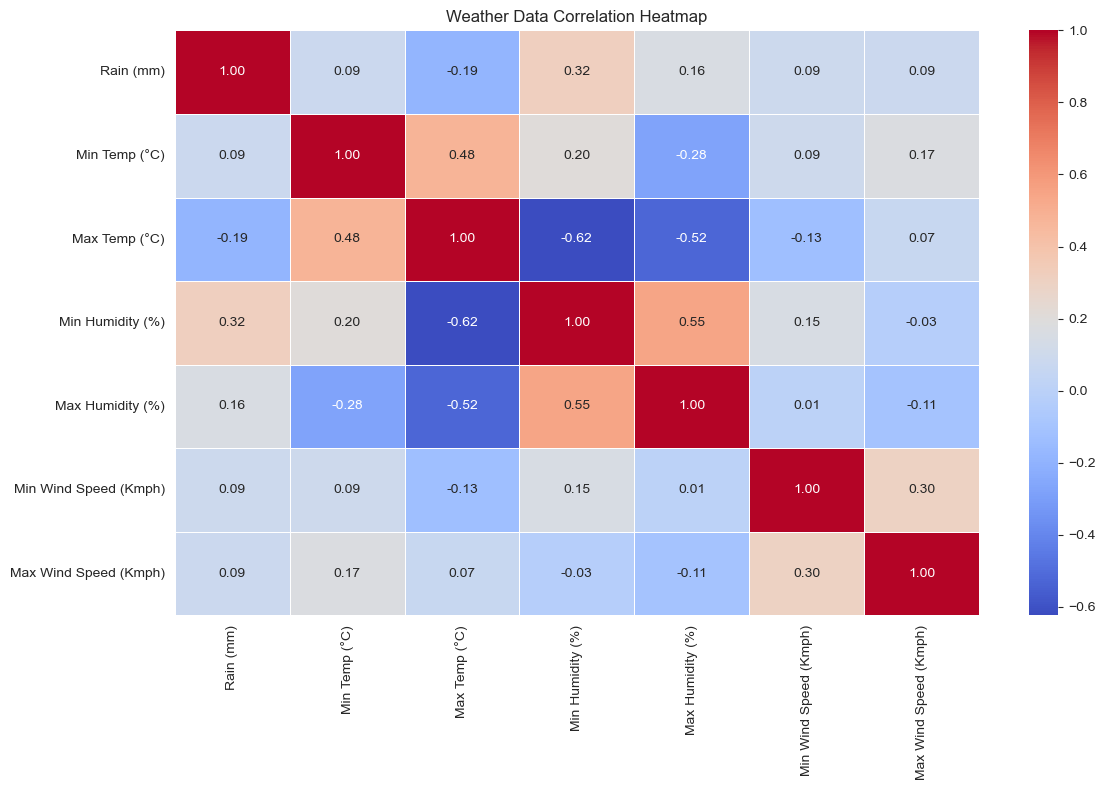

<Figure size 640x480 with 0 Axes>

In [26]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Weather Data Correlation Heatmap")
plt.tight_layout()
plt.show()
plt.savefig("Weather Data Correlation Heatmap.png",dpi=300)

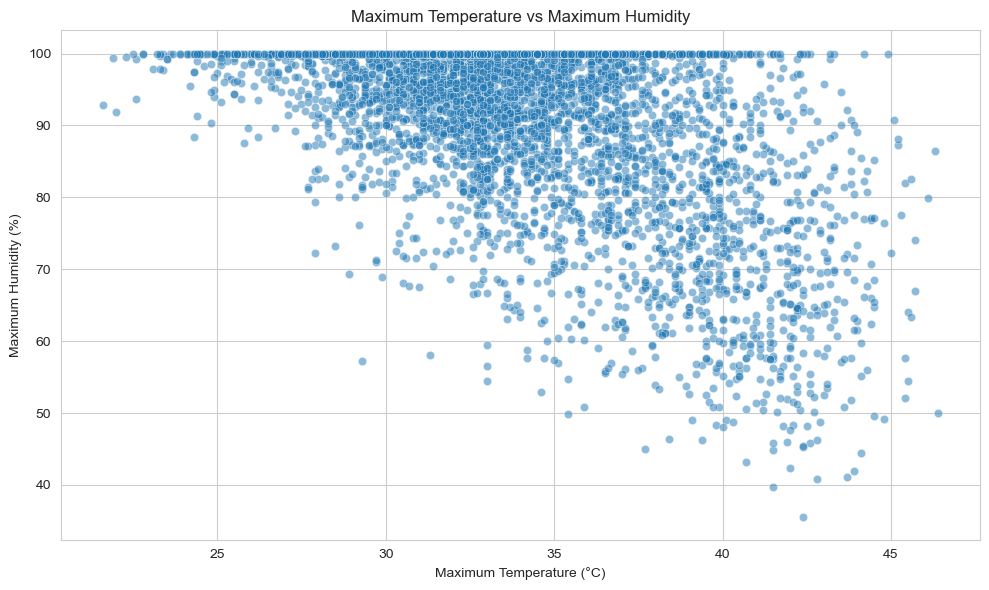

In [27]:
sample_df = df.sample(
    min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x="Max Temp (°C)",
    y="Max Humidity (%)",
    alpha=0.5
)

plt.title("Maximum Temperature vs Maximum Humidity")
plt.xlabel("Maximum Temperature (°C)")
plt.ylabel("Maximum Humidity (%)")
plt.tight_layout()
plt.show()

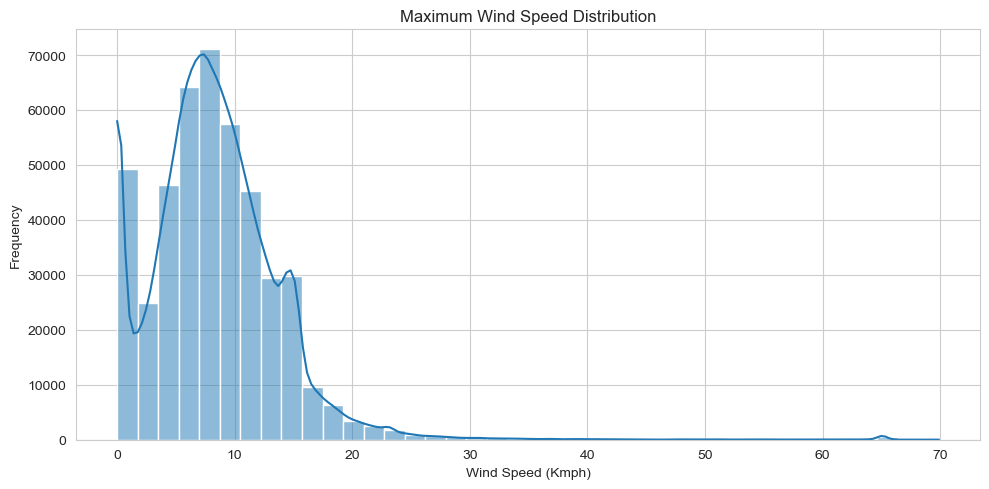

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Max Wind Speed (Kmph)"].dropna(),
    bins=40,
    kde=True
)

plt.title("Maximum Wind Speed Distribution")
plt.xlabel("Wind Speed (Kmph)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [29]:
print("All Weather Data Visualization Completed!")

All Weather Data Visualization Completed!


#3.prediction models

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [31]:
df = pd.read_csv("weather_data_cleaned.csv")

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

print(df.head())
print(df.shape)

   District          Mandal       Date  Rain (mm)  Min Temp (°C)  \
0  Adilabad  Adilabad Rural 2023-02-01        0.0           16.6   
1  Adilabad  Adilabad Rural 2023-02-02        0.0           13.7   
2  Adilabad  Adilabad Rural 2023-02-03        0.0           10.3   
3  Adilabad  Adilabad Rural 2023-02-04        0.0           11.7   
4  Adilabad  Adilabad Rural 2023-02-05        0.0            9.2   

   Max Temp (°C)  Min Humidity (%)  Max Humidity (%)  Min Wind Speed (Kmph)  \
0           30.9              49.3              82.0                    0.0   
1           28.7              46.4              81.1                    0.0   
2           29.5              24.2              55.8                    0.0   
3           30.3              26.3              59.9                    0.0   
4           31.3              25.2              57.6                    0.0   

   Max Wind Speed (Kmph)  
0                   11.4  
1                   12.0  
2                   10.9  
3       

In [32]:
features = [
    "Min Temp (°C)",
    "Max Temp (°C)",
    "Min Humidity (%)",
    "Max Humidity (%)",
    "Min Wind Speed (Kmph)",
    "Max Wind Speed (Kmph)"
]

X = df[features]
y = df["Rain (mm)"]

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Input Features: (445212, 6)
Target Variable: (445212,)


In [33]:
df = df.dropna(subset=["Date", "Rain (mm)"])
df = df.sort_values("Date")

# Add seasonal features
df["Month"] = df["Date"].dt.month
df["Day_of_Year"] = df["Date"].dt.dayofyear

features = [
    "Min Temp (°C)",
    "Max Temp (°C)",
    "Min Humidity (%)",
    "Max Humidity (%)",
    "Min Wind Speed (Kmph)",
    "Max Wind Speed (Kmph)",
    "Month",
    "Day_of_Year"
]

X = df[features]
y = df["Rain (mm)"]

# Chronological split
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (356169, 8)
Testing data: (89043, 8)


In [34]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(
            max_depth=12,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ])
}

In [35]:
trained_models = {}

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    trained_models[name] = model

print("All models trained successfully!")

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting
All models trained successfully!


In [36]:
results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(
        y_test, predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values("RMSE"))

               Model       MAE      RMSE  R2 Score
3  Gradient Boosting  1.959294  4.897993  0.059389
2      Random Forest  1.666870  5.207563 -0.063268
1      Decision Tree  1.649329  5.699014 -0.273425
0  Linear Regression  4.244976  6.049762 -0.434995


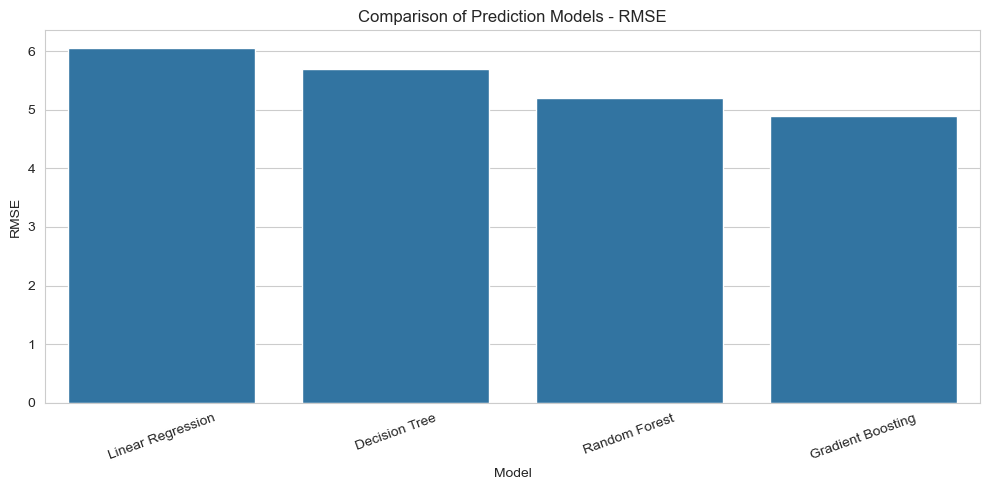

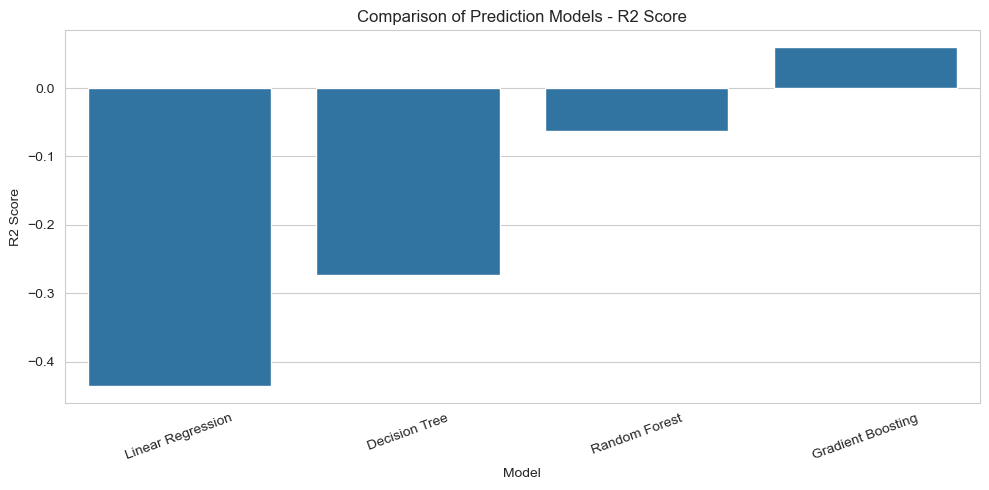

In [37]:
# RMSE comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Comparison of Prediction Models - RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# R2 score comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Prediction Models - R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

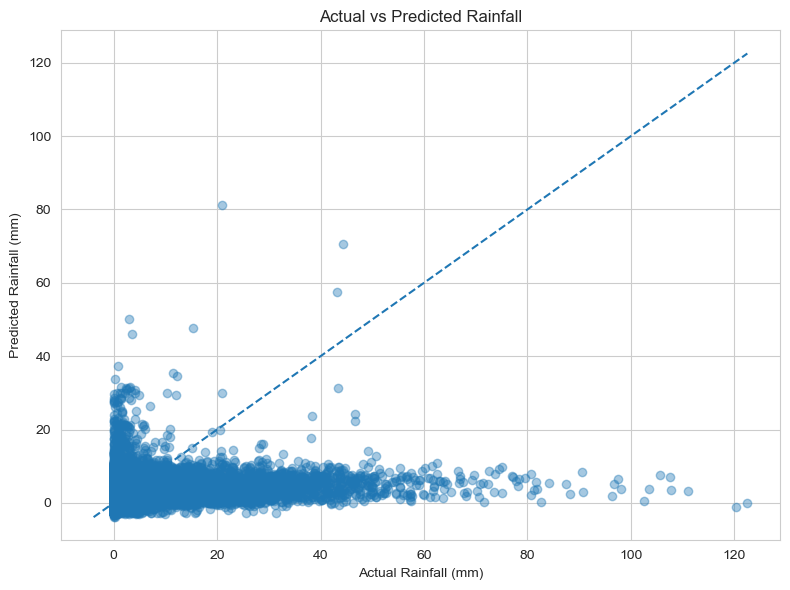

Best Model: Gradient Boosting


In [38]:
best_model_name = results_df.sort_values(
    "RMSE"
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.4
)

min_value = min(y_test.min(), predictions.min())
max_value = max(y_test.max(), predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Rainfall (mm)")
plt.ylabel("Predicted Rainfall (mm)")
plt.title("Actual vs Predicted Rainfall")

plt.tight_layout()
plt.show()

print("Best Model:", best_model_name)

In [39]:
import joblib

joblib.dump(
    best_model,
    "best_rainfall_prediction_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


#4.Dashboard Creation

In [40]:
pip install streamlit pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [ ]:

import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

# ==================================
# 1. PAGE CONFIGURATION
# ==================================

st.set_page_config(
    page_title="Weather Prediction Dashboard",
    page_icon="🌦️",
    layout="wide"
)

st.title("🌦️ Weather Analytics & Prediction Dashboard")
st.write("Weather Data Analysis and Rainfall Prediction System")

sns.set_style("whitegrid")

# ==================================
# 2. LOAD DATASET
# ==================================

@st.cache_data
def load_data():
    data = pd.read_csv("weather_data_cleaned.xls")
    data["Date"] = pd.to_datetime(
        data["Date"], errors="coerce"
    )
    return data

df = load_data()

# Load trained model
model = None

if os.path.exists("best_rainfall_prediction_model.pkl"):
    model = joblib.load(
        "best_rainfall_prediction_model.pkl"
    )

# ==================================
# 3. SIDEBAR NAVIGATION
# ==================================

st.sidebar.title("Navigation")

page = st.sidebar.radio(
    "Select Dashboard Page",
    [
        "Overview",
        "Weather Analysis",
        "District Analysis",
        "Rainfall Prediction"
    ]
)

# ==================================
# 4. OVERVIEW PAGE
# ==================================

if page == "Overview":

    st.header("Weather Dataset Overview")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Total Records", f"{len(df):,}")
    col2.metric("Total Columns", len(df.columns))
    col3.metric(
        "Total Districts",
        df["District"].nunique()
    )
    col4.metric(
        "Average Rainfall",
        f"{df['Rain (mm)'].mean():.2f} mm"
    )

    st.subheader("Dataset Preview")

    st.dataframe(df.head(20), use_container_width=True)

    st.subheader("Dataset Statistics")

    st.dataframe(
        df.describe(),
        use_container_width=True
    )

    st.subheader("Missing Values")

    missing = df.isnull().sum()

    st.bar_chart(missing)

# ==================================
# 5. WEATHER ANALYSIS PAGE
# ==================================

elif page == "Weather Analysis":

    st.header("Weather Data Analysis")

    st.subheader("Rainfall Distribution")

    fig, ax = plt.subplots(figsize=(10, 5))

    sns.histplot(
        df["Rain (mm)"].dropna(),
        bins=50,
        kde=True,
        ax=ax
    )

    ax.set_xlabel("Rainfall (mm)")
    ax.set_ylabel("Frequency")

    st.pyplot(fig)
    plt.close(fig)

    st.subheader("Monthly Average Rainfall")

    monthly = df.groupby(
        df["Date"].dt.month
    )["Rain (mm)"].mean()

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        monthly.index,
        monthly.values,
        marker="o"
    )

    ax.set_xlabel("Month")
    ax.set_ylabel("Average Rainfall (mm)")
    ax.set_xticks(range(1, 13))
    ax.grid()

    st.pyplot(fig)
    plt.close(fig)

    st.subheader("Temperature Analysis")

    fig, ax = plt.subplots(figsize=(10, 5))

    sns.histplot(
        df["Min Temp (°C)"].dropna(),
        label="Minimum Temperature",
        kde=True,
        ax=ax
    )

    sns.histplot(
        df["Max Temp (°C)"].dropna(),
        label="Maximum Temperature",
        kde=True,
        ax=ax
    )

    ax.legend()

    st.pyplot(fig)
    plt.close(fig)

    st.subheader("Correlation Heatmap")

    numeric = df.select_dtypes(include=np.number)

    fig, ax = plt.subplots(figsize=(11, 7))

    sns.heatmap(
        numeric.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        ax=ax
    )

    st.pyplot(fig)
    plt.close(fig)

# ==================================
# 6. DISTRICT ANALYSIS PAGE
# ==================================

elif page == "District Analysis":

    st.header("District-wise Weather Analysis")

    districts = sorted(
        df["District"].dropna().unique()
    )

    selected_district = st.selectbox(
        "Select District",
        districts
    )

    district_data = df[
        df["District"] == selected_district
    ]

    st.subheader(
        f"Weather Statistics: {selected_district}"
    )

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Average Rainfall",
        f"{district_data['Rain (mm)'].mean():.2f} mm"
    )

    col2.metric(
        "Average Temperature",
        f"{district_data['Max Temp (°C)'].mean():.2f} °C"
    )

    col3.metric(
        "Average Humidity",
        f"{district_data['Max Humidity (%)'].mean():.2f} %"
    )

    st.subheader("District Rainfall Trend")

    monthly_district = district_data.groupby(
        district_data["Date"].dt.month
    )["Rain (mm)"].mean()

    st.line_chart(monthly_district)

    st.subheader("Top 10 Districts by Average Rainfall")

    top_districts = (
        df.groupby("District")["Rain (mm)"]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    st.bar_chart(top_districts)

# ==================================
# 7. RAINFALL PREDICTION PAGE
# ==================================

elif page == "Rainfall Prediction":

    st.header("🌧️ Rainfall Prediction")

    st.write(
        "Enter weather measurements to estimate rainfall."
    )

    if model is None:

        st.error(
            "Trained model not found. "
            "Please run your machine learning training "
            "script and save the model first."
        )

    else:

        col1, col2 = st.columns(2)

        with col1:

            min_temp = st.number_input(
                "Minimum Temperature (°C)",
                value=20.0
            )

            max_temp = st.number_input(
                "Maximum Temperature (°C)",
                value=30.0
            )

            min_humidity = st.number_input(
                "Minimum Humidity (%)",
                min_value=0.0,
                max_value=100.0,
                value=40.0
            )

            max_humidity = st.number_input(
                "Maximum Humidity (%)",
                min_value=0.0,
                max_value=100.0,
                value=80.0
            )

        with col2:

            min_wind = st.number_input(
                "Minimum Wind Speed (Kmph)",
                min_value=0.0,
                value=5.0
            )

            max_wind = st.number_input(
                "Maximum Wind Speed (Kmph)",
                min_value=0.0,
                value=15.0
            )

            selected_date = st.date_input(
                "Select Date"
            )

        if st.button("Predict Rainfall"):

            if min_temp > max_temp:
                st.error("Minimum temperature cannot exceed maximum temperature.")

            elif min_humidity > max_humidity:
                st.error("Minimum humidity cannot exceed maximum humidity.")

            elif min_wind > max_wind:
                st.error("Minimum wind speed cannot exceed maximum wind speed.")

            else:

                month = selected_date.month
                day_of_year = selected_date.timetuple().tm_yday

                input_data = pd.DataFrame([{
                    "Min Temp (°C)": min_temp,
                    "Max Temp (°C)": max_temp,
                    "Min Humidity (%)": min_humidity,
                    "Max Humidity (%)": max_humidity,
                    "Min Wind Speed (Kmph)": min_wind,
                    "Max Wind Speed (Kmph)": max_wind,
                    "Month": month,
                    "Day_of_Year": day_of_year
                }])

                prediction = model.predict(input_data)[0]

                prediction = max(0, prediction)

                st.success("Prediction Completed!")

                st.metric(
                    "Predicted Rainfall",
                    f"{prediction:.2f} mm"
                )

                if prediction == 0:
                    st.info("The model predicts no measurable rainfall.")
                else:
                    st.info(
                        f"Estimated rainfall: {prediction:.2f} mm"
                    )

# ==================================
# 8. FOOTER
# ==================================

st.sidebar.markdown("---")
st.sidebar.write("Weather Prediction Project")
st.sidebar.caption("Developed using Python & Streamlit")